# 4. Soft running corridor with an explicit modeling slack

**Goal:** regulate the scalar state while preferring $|x_k|\le1$.
The initial state is 2.5, so a hard running corridor would be infeasible at $k=0$.
Introduce a nonnegative decision variable $\epsilon_k$:

$$\begin{aligned}
\min\quad &\frac12\sum_{k=0}^{N-1}(x_k^2+0.2a_k^2+0.1\epsilon_k^2)
 +5\sum_{k=0}^{N-1}\epsilon_k+\frac12\,8x_N^2\\
\text{subject to}\quad &x_{k+1}=x_k+0.25a_k,\quad x_0=2.5,\quad x_N=0,\\
&|a_k|\le1,\quad\epsilon_k\ge0,\quad |x_k|\le1+\epsilon_k.
\end{aligned}$$

$\epsilon$ is a **modeling slack**, not the solver's internal IPM slack `solution["s"]`.
Terminal dynamics and the terminal target stay hard.


Run the cells from top to bottom. The first `Solver(...)` may compile the native
library. That is setup, not solve time. Installation instructions: [README](../README.md).

All model arrays are constructed below: there is no hidden model builder.
`explain_solution` only checks and reports the already-computed solution.

> **Development transparency:** Substantial portions of ICORE's implementation and documentation were generated and revised with GPT under human direction. Not all details have undergone independent human review. See the [development and review statement](../README.md#development-transparency-and-review-status).


In [1]:
# Locate the repository whether Jupyter starts here or in the parent folder.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "icore" / "api.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from icore import Solver
from example_tools.tutorial import explain_solution

BACKEND = "cpp"           # "c" or "cpp"; both use the same numerical algorithm.
TOLERANCE = 1e-8
USE_PRESOLVE = True
DETAILED = False           # True: one extra untimed replay, with expandable details.

## 1. Dynamics: the slack has no physical effect

In [2]:
N, nx, nu = 20, 1, 2
dt = 0.25
A = np.ones((N, nx, nx))
B = np.zeros((N, nx, nu))
B[:, 0, 0] = dt          # u = [physical acceleration, epsilon].
b = np.zeros((N, nx))
x0 = np.array([2.5])

## 2. Cost
The linear slack penalty discourages violation; the quadratic term is modest.

In [3]:
Q = np.ones((N + 1, nx, nx))
Q[-1] = 8.0
R = np.tile(np.diag([0.2, 0.1]), (N, 1, 1))
S = np.zeros((N, nu, nx))
q = np.zeros((N + 1, nx))
r = np.zeros((N, nu))
r[:, 1] = 5.0
objective_offset = 0.0

## 3. Soft running rows, hard terminal equality
All columns are `[physical input, epsilon, state]`.

In [4]:
G = np.zeros((N + 1, 5, nu + nx))
h = np.ones((N + 1, 5))
G[:N, 0, 0], G[:N, 1, 0] = 1.0, -1.0
G[:N, 2, 1], h[:N, 2] = -1.0, 0.0     # epsilon >= 0.
G[:N, 3, 1], G[:N, 3, 2] = -1.0, 1.0 # x - epsilon <= 1.
G[:N, 4, 1], G[:N, 4, 2] = -1.0, -1.0
# No terminal epsilon. The terminal corridor is hard (and compatible with x_N=0).
G[N, 3, 2], G[N, 4, 2] = 1.0, -1.0
F = np.ones((1, nx))
f = np.zeros(1)

## 4. Give the arrays to ICORE and solve

`[u, x]` is the column order in each constraint row. The block cost is
$\tfrac12x^TQx + u^TSx + \tfrac12u^TRu + q^Tx + r^Tu$.
`F @ x[N] = f` is an optional terminal equality. An empty `F, f` means none.

The kernel and counters below come from the actual solve. A factorization policy
is **not** claimed to be a trace of every operation. Set `DETAILED=True` above
for an additional diagnostic replay; it is separate from solve timing.

In [5]:
problem = dict(
    A=A, B=B, b=b, x0=x0,
    Q=Q, R=R, S=S, q=q, r=r,
    G=G, h=h, F=F, f=f,
)

with Solver(problem, backend=BACKEND, tolerance=TOLERANCE,
            structural_presolve=USE_PRESOLVE) as solver:
    solution = solver.solve()
    report = explain_solution(solver, solution, problem,
                              objective_offset=objective_offset, detailed=DETAILED)

# Solver returns your original coordinates, including when presolve was applied.
x = solution["x"]        # Shape (N + 1, nx).
u = solution["u"]        # Shape (N, nu); there is no terminal control.
print("Initial state:", x[0])
print("Final state:", x[-1])
print("First input:", u[0])

### What the solver actually did

Property,Value
Backend,C++
Status / iterations,Passed / 7
Native solve (ms),0.112000
Structural presolve requested,Yes
Exact OCP-to-chain reduction applied,No
Actual kernel,General OCP / Riccati kernel
Reason,The general stage-structured OCP representation was retained.
Factorization policy (not a trace),Automatic Riccati; QR recovery supports terminal equalities
Factor retries / refinement steps,0 / 0
Dense-to-OCP numerical fallbacks,0


The optional chain-reduction certificate was rejected; keeping the general OCP is expected, not an error.

### Accuracy in the original problem

primal error,dual error,complementarity,dynamics error,terminal error,objective (including constant),passed
1.776e-15,7.994e-15,2.253e-10,1.110e-16,5.294e-23,39.504053,True


Native solve time excludes compilation, model setup, this audit, and plotting. Counters do not list every factorization attempt or every reason a fast path was rejected.

Initial state: [2.5]
Final state: [-5.29427672e-23]
First input: [-1.   1.5]


## 5. Inspect the violation explicitly

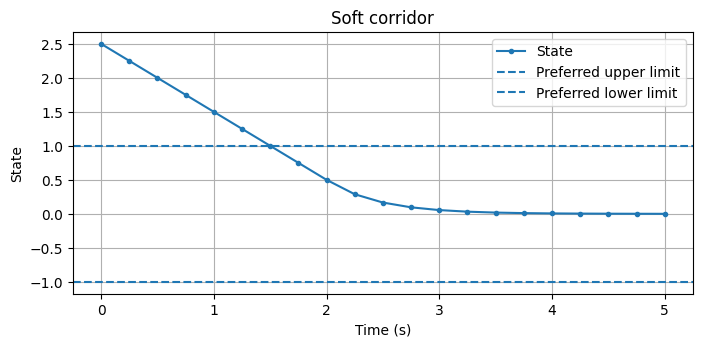

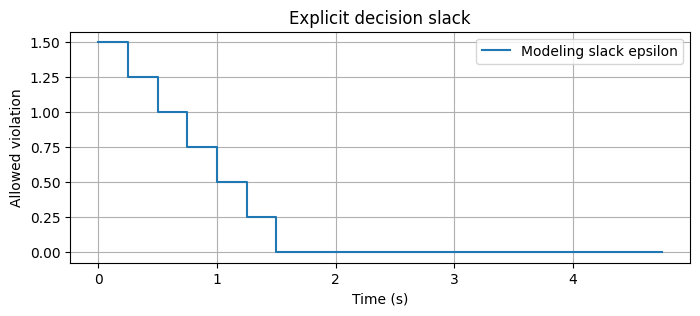

Initial slack (must be at least 1.5): 1.5000000000000009


In [6]:
epsilon = u[:, 1]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(dt * np.arange(N + 1), x[:, 0], marker=".", label="State")
ax.axhline(1.0, linestyle="--", label="Preferred upper limit")
ax.axhline(-1.0, linestyle="--", label="Preferred lower limit")
ax.set(xlabel="Time (s)", ylabel="State", title="Soft corridor")
ax.grid(True)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.0))
ax.step(dt * np.arange(N), epsilon, where="post", label="Modeling slack epsilon")
ax.set(xlabel="Time (s)", ylabel="Allowed violation", title="Explicit decision slack")
ax.grid(True)
ax.legend()
plt.show()
print("Initial slack (must be at least 1.5):", epsilon[0])
assert epsilon[0] >= 1.5 - TOLERANCE

## Modeling tip
Use a penalty meaningful in the units of the problem. Making it enormous is not automatically
better and can worsen conditioning. This soft formulation is intentionally **not equivalent**
to the hard, infeasible corridor. The solver does not choose that modeling decision for you.

Next: [Euclidean norm limits with SOCs](05_planar_soc.ipynb).